In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [5]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [6]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [7]:
import cmocean
from scipy import stats

In [8]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [9]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [10]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [11]:
import regionmask

In [12]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [14]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [15]:
import sys

In [16]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [17]:
from functions import preproc_funcs as funcs

In [18]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    
]

In [19]:
pr_regr_obs_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_obs_1950_2014.nc')
pr_regr_rean_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_rean_1950_2014.nc')

pr_regr_obs_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_rean_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [20]:
delta_pr_regr_obs = (pr_regr_obs_30y.regr - pr_regr_obs_baseline.regr)
delta_pr_regr_rean = (pr_regr_rean_30y.regr - pr_regr_rean_baseline.regr)

In [21]:
pr_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_baseline.nc')
pr_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_mid_century.nc')
pr_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_end_century.nc')

In [22]:
delta_pr_regr_cmip6_midc  = (pr_regr_cmip6_midc.regr - pr_regr_cmip6_baseline.regr)
delta_pr_regr_cmip6_endc  = (pr_regr_cmip6_endc.regr - pr_regr_cmip6_baseline.regr)

In [23]:
ts_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
ts_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_mid_century.nc')
ts_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_end_century.nc')

In [24]:
delta_ts_regr_cmip6_midc  = (ts_regr_cmip6_midc.regr - ts_regr_cmip6_baseline.regr)
delta_ts_regr_cmip6_endc  = (ts_regr_cmip6_endc.regr - ts_regr_cmip6_baseline.regr)

In [25]:
model = model_list[1]
model

'CESM1-CAM5'

In [26]:
def _preprocess(da):
    if 'height' in da.coords:
        da = da.drop('height')
    return da

In [27]:

## calculating model_uncertainty and internal variabiltiy uncertainty
pr_regr_smile_baseline_means = []
pr_regr_smile_baseline_vars = []

delta_pr_regr_smile_midc_means = []
delta_pr_regr_smile_midc_vars = []

delta_pr_regr_smile_endc_means = []
delta_pr_regr_smile_endc_vars = []


for model in model_list:
    pr_regr_smile_baseline = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc', preprocess=_preprocess).regr
    pr_regr_smile_baseline_means.append(pr_regr_smile_baseline.mean('model'))
    pr_regr_smile_baseline_vars.append(pr_regr_smile_baseline.var('model'))
    #
    delta_pr_regr_smile_midc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_mid_century.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    delta_pr_regr_smile_midc_means.append(delta_pr_regr_smile_midc.mean('model'))
    delta_pr_regr_smile_midc_vars.append(delta_pr_regr_smile_midc.var('model'))
    #
    delta_pr_regr_smile_endc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_end_century.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    delta_pr_regr_smile_endc_means.append(delta_pr_regr_smile_endc.mean('model'))
    delta_pr_regr_smile_endc_vars.append(delta_pr_regr_smile_endc.var('model'))
    #
    print(f'Completed {model}')


pr_regr_smile_baseline_means = xr.concat(pr_regr_smile_baseline_means, dim='smile')
pr_regr_smile_baseline_means['smile'] = model_list
pr_regr_smile_baseline_vars = xr.concat(pr_regr_smile_baseline_vars, dim='smile')
pr_regr_smile_baseline_vars['smile'] = model_list


delta_pr_regr_smile_midc_means = xr.concat(delta_pr_regr_smile_midc_means, dim='smile').load()
delta_pr_regr_smile_midc_means['smile'] = model_list
delta_pr_regr_smile_midc_vars = xr.concat(delta_pr_regr_smile_midc_vars, dim='smile').load()
delta_pr_regr_smile_midc_vars['smile'] = model_list

delta_pr_regr_smile_endc_means = xr.concat(delta_pr_regr_smile_endc_means, dim='smile').load()
delta_pr_regr_smile_endc_means['smile'] = model_list
delta_pr_regr_smile_endc_vars = xr.concat(delta_pr_regr_smile_endc_vars, dim='smile').load()
delta_pr_regr_smile_endc_vars['smile'] = model_list
print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


### All existing datasets


1. OBS 30-year uncertainty - Var(delta_pr_regr_obs)
2. REAN 30-year uncertainty - Var(delta_pr_regr_rean)
3. SMILE 30-year internal variability uncertainty - Mean(delta_pr_regr_smile_endc_vars)
4. SMILE 30-year model uncertainty - Var(delta_pr_regr_smile_endc_means)
5. CMIP6 30-year model uncertainty only - Var(delta_pr_regr_cmip6_endc) (this is a measure of **model uncertainty** and can be used to constrain SMILE uncertainty)

In [28]:
plot_list = [
    pr_regr_obs_baseline.regr,
    pr_regr_obs_30y.regr.max('ey'),
    pr_regr_obs_30y.regr.min('ey'),
    # pr_regr_obs_30y.regr.var('ey'),
]

labels_list = [
    'a', 'b', 'c'#, 'd'
]

titles_list = [
    '$P_\sigma - N3.4 (1950 - 2014)$',
    '$P_\sigma - N3.4 (30y-max)$',
    '$P_\sigma - N3.4 (30y-min)$',
    # '$P_\sigma ~ N3.4 (30y var)$',
]

pval_list = [
    pr_regr_obs_baseline.pval,
    np.ones_like(pr_regr_obs_baseline.pval),
    np.ones_like(pr_regr_obs_baseline.pval),
    # np.ones_like(pr_regr_obs_baseline.pval),
]


In [29]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='BrBG', levels=np.linspace(-1, 1, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Regression (mm std$^{-1}$ / degC)', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$P_\\sigma - N3.4 (1950 - 2014)$'}, xlabel='lon', ylabel='lat'>

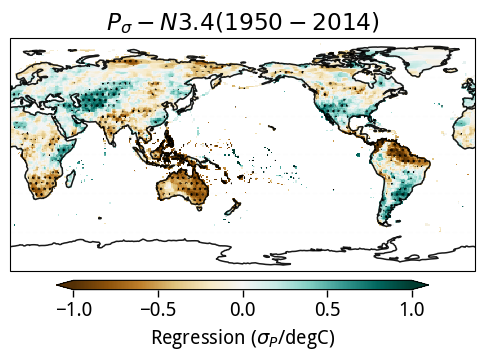

In [30]:
zz = plot_list[0]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[0])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-max)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

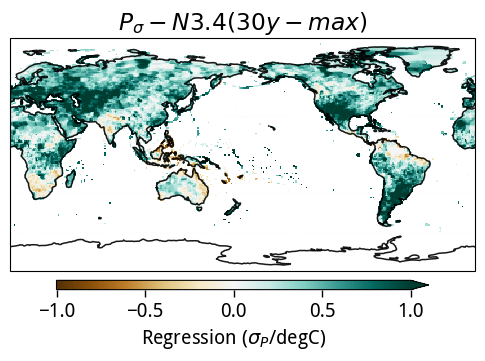

In [31]:
zz = plot_list[1]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-min)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

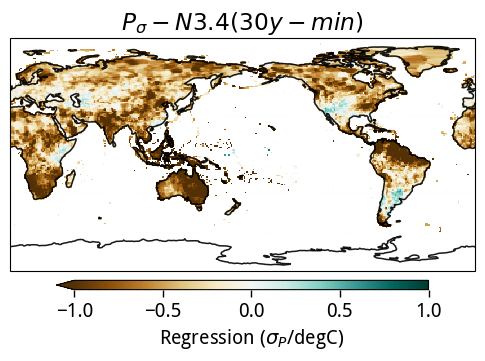

In [32]:
zz = plot_list[2]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[2])
plot_background(ax)


In [33]:
# zz = pr_regr_obs_30y.regr.var('ey')

# xx, yy = np.meshgrid(zz.lon, zz.lat)


# plot_single_map(xx, yy, zz, title='$P_\sigma ~ N3.4 (30y var)$', label='d', cmap='viridis', levels=np.linspace(0, 0.2, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Variance', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$p_\\sigma ~ n3.4 (30y-std.dev.)$'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

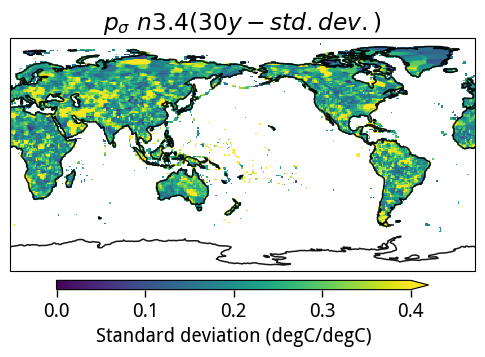

In [32]:
zz = pr_regr_obs_30y.regr.std('ey')
# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0, vmax=0.4, cmap='viridis', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Standard deviation (degC/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title('$p_\sigma ~ n3.4 (30y-std.dev.)$')
plot_background(ax)


In [33]:
plot_list = [
    pr_regr_rean_baseline.regr,
    pr_regr_rean_30y.regr.max('ey'),
    pr_regr_rean_30y.regr.min('ey'),
    # pr_regr_rean_30y.regr.var('ey'),
]

labels_list = [
    'a', 'b', 'c'#, 'd'
]

titles_list = [
    '$P_\sigma - N3.4 (1950 - 2014)$',
    '$P_\sigma - N3.4 (30y-max)$',
    '$P_\sigma - N3.4 (30y-min)$',
    # '$P_\sigma ~ N3.4 (30y var)$',
]

pval_list = [
    pr_regr_rean_baseline.pval,
    np.ones_like(pr_regr_rean_baseline.pval),
    np.ones_like(pr_regr_rean_baseline.pval),
    # np.ones_like(pr_regr_rean_baseline.pval),
]


In [34]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='BrBG', levels=np.linspace(-1, 1, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Regression (mm std$^{-1}$ / degC)', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [35]:
# zz = pr_regr_rean_30y.regr.var('ey')

# xx, yy = np.meshgrid(zz.lon, zz.lat)


# plot_single_map(xx, yy, zz, title='$P_\sigma ~ N3.4 (30y var)$', label='d', cmap='viridis', levels=np.linspace(0, 0.2, 21), add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Variance', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': '$P_\\sigma - N3.4 (1950 - 2014)$'}, xlabel='lon', ylabel='lat'>

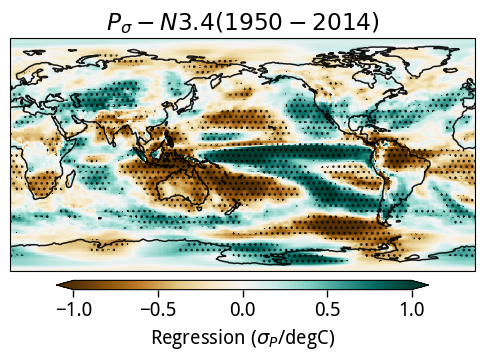

In [36]:
zz = plot_list[0]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[0])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-max)$'}, xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

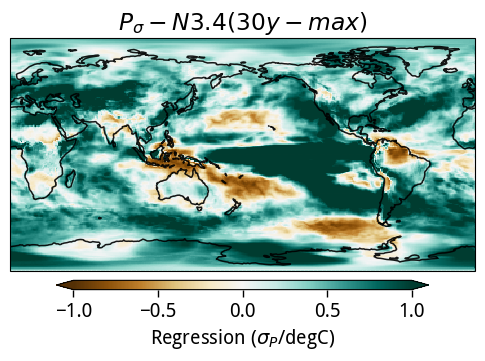

In [57]:
zz = plot_list[1]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': '$P_\\sigma - N3.4 (30y-min)$'}, xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

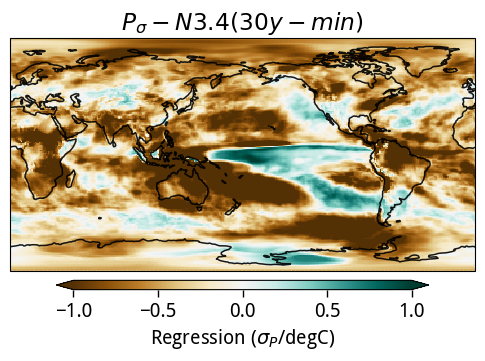

In [58]:
zz = plot_list[2]
xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1, vmax=1, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title(titles_list[2])
plot_background(ax)


<GeoAxes: title={'center': '$p_\\sigma - n3.4 (30y-std.dev.)$'}, xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

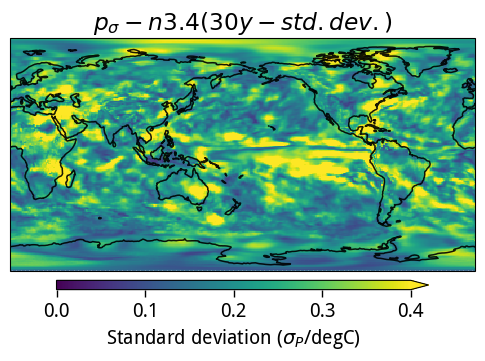

In [59]:
zz = pr_regr_rean_30y.regr.std('ey')
# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0, vmax=0.4, cmap='viridis', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Standard deviation ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())
# zp = np.ma.masked_greater_equal(pval_list[0], 0.05)
# ax.pcolor(xx, yy, zp, alpha=0., hatch='...', transform=ccrs.PlateCarree())
ax.set_title('$p_\sigma - n3.4 (30y-std.dev.)$')
plot_background(ax)


In [34]:
import xesmf as xe

In [35]:
regridder_rean = xe.Regridder(pr_regr_rean_baseline, pr_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)
regridder_obs = xe.Regridder(pr_regr_obs_baseline, pr_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)

In [39]:
# zz = delta_pr_regr_smile_midc_means.mean('smile')
# zp = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
# zp2 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
# xx, yy = np.meshgrid(zz.lon, zz.lat)



# ax = plot_single_tele_delta(xx, yy, zz, title='', label='d', cmap='BrBG', levels=np.linspace(-0.7, 0.7, 21), add_sign=True, pval = zp, pval2 = zp2, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Regression change (degC/degC)', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [40]:
# zz = delta_pr_regr_smile_endc_means.mean('smile')
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
# zp2 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
# xx, yy = np.meshgrid(zz.lon, zz.lat)



# ax = plot_single_tele_delta(xx, yy, zz, title='', label='d', cmap='BrBG', levels=np.linspace(-0.7, 0.7, 21), add_sign=True, pval = zp, pval2 = zp2, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Regression change (degC/degC)', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

In [41]:
# zz = delta_pr_regr_cmip6_endc.mean('model')
# zp = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp2 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
# xx, yy = np.meshgrid(zz.lon, zz.lat)



# ax = plot_single_tele_delta(xx, yy, zz, title='', label='d', cmap='BrBG', levels=np.linspace(-0.7, 0.7, 21), add_sign=True, pval = zp, pval2 = zp2, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#                 figsize=(7,8), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.PlateCarree(central_longitude=180), 
#                 cbar_kwargs=dict(orientation='horizontal', label='Regression change (degC/degC)', aspect=40, shrink=1.1, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': 'Baseline 1950-2014'}, xlabel='lon', ylabel='lat'>

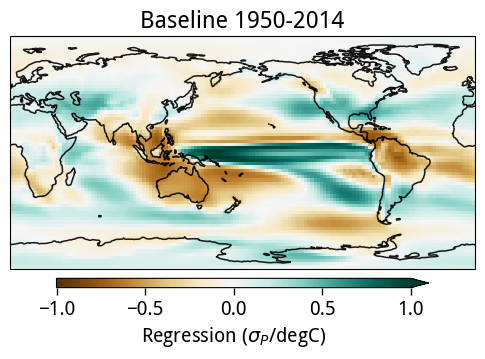

In [42]:
zz = pr_regr_smile_baseline_means.mean('smile')
# zp = pr_regr_cmip6_baseline.pval
xx, yy = np.meshgrid(zz.lon, zz.lat)



plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1.0, vmax=1.0, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())

# zp1_plot = np.ma.masked_less(zp1, 1)
# ax.pcolor(xx, yy, zp1_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
# zp2_plot = np.ma.masked_less(zp2, 1)
# ax.pcolor(xx, yy, zp2_plot, alpha=0., hatch='xxx', transform=ccrs.PlateCarree())

ax.set_title('Baseline 1950-2014')
plot_background(ax)


<GeoAxes: title={'center': 'Near term $\\Delta$ 2030-2060'}, xlabel='lon', ylabel='lat'>

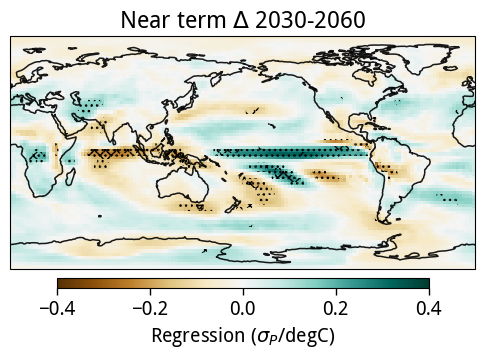

In [53]:
zz = delta_pr_regr_smile_midc_means.mean('smile')
zp1 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)



plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -0.4, vmax=0.4, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())

zp1_plot = np.ma.masked_less(zp1, 1)
ax.pcolor(xx, yy, zp1_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
zp2_plot = np.ma.masked_less(zp2, 1)
ax.pcolor(xx, yy, zp2_plot, alpha=0., hatch='xxx', transform=ccrs.PlateCarree())

ax.set_title('Near term $\Delta$ 2030-2060')
plot_background(ax)


<GeoAxes: title={'center': 'Long term $\\Delta$ 2070-2100'}, xlabel='lon', ylabel='lat'>

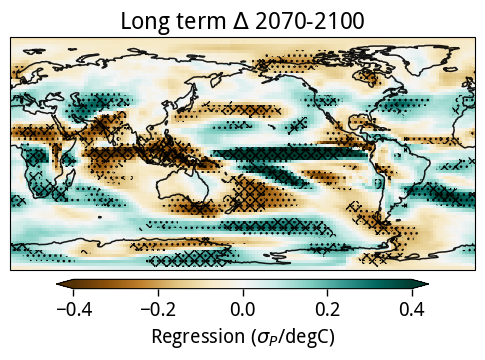

In [54]:
zz = delta_pr_regr_smile_endc_means.mean('smile')
zp1 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_endc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -0.4, vmax=0.4, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())

zp1_plot = np.ma.masked_less(zp1, 1)
ax.pcolor(xx, yy, zp1_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
zp2_plot = np.ma.masked_less(zp2, 1)
ax.pcolor(xx, yy, zp2_plot, alpha=0., hatch='xxx', transform=ccrs.PlateCarree())

ax.set_title('Long term $\Delta$ 2070-2100')
plot_background(ax)


<GeoAxes: title={'center': 'Baseline 1950-2014'}, xlabel='lon', ylabel='lat'>

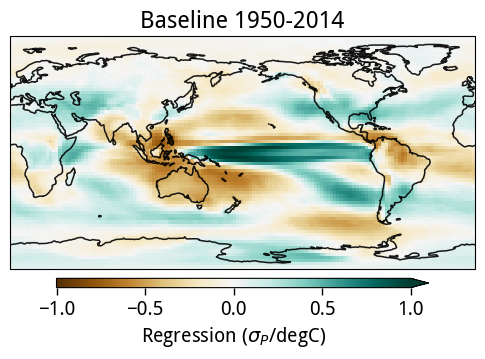

In [36]:
zz = pr_regr_cmip6_baseline.regr.mean('model')
# zp = pr_regr_cmip6_baseline.pval
xx, yy = np.meshgrid(zz.lon, zz.lat)



plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -1.0, vmax=1.0, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())

# zp1_plot = np.ma.masked_less(zp1, 1)
# ax.pcolor(xx, yy, zp1_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
# zp2_plot = np.ma.masked_less(zp2, 1)
# ax.pcolor(xx, yy, zp2_plot, alpha=0., hatch='xxx', transform=ccrs.PlateCarree())

ax.set_title('Baseline 1950-2014')
plot_background(ax)


In [37]:
def ttest_ind1d(a, b):
    _, p = stats.ttest_ind(a,b, equal_var=False)
    return p


def ttest_ind3d(da1, da2, dim='model'):
    return xr.apply_ufunc(ttest_ind1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

<GeoAxes: title={'center': 'Near term $\\Delta$ 2030-2060'}, xlabel='lon', ylabel='lat'>

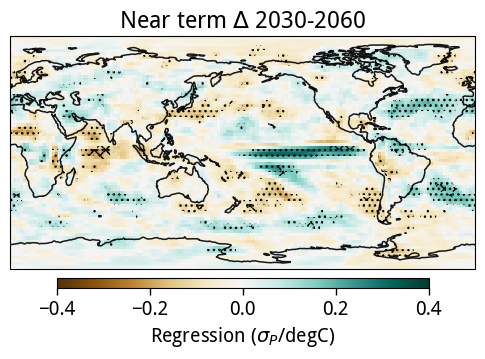

In [40]:
zz = delta_pr_regr_cmip6_midc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_midc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -0.4, vmax=0.4, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())

zp_plot = np.ma.masked_greater_equal(zp, 0.05)
ax.pcolor(xx, yy, zp_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
# zp1_plot = np.ma.masked_less(zp1, 1)
# ax.pcolor(xx, yy, zp1_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
zp2_plot = np.ma.masked_less(zp2, 1)
ax.pcolor(xx, yy, zp2_plot, alpha=0., hatch='xxx', transform=ccrs.PlateCarree())

ax.set_title('Near term $\Delta$ 2030-2060')
plot_background(ax)


<GeoAxes: title={'center': 'Long term $\\Delta$ 2070-2100'}, xlabel='lon', ylabel='lat'>

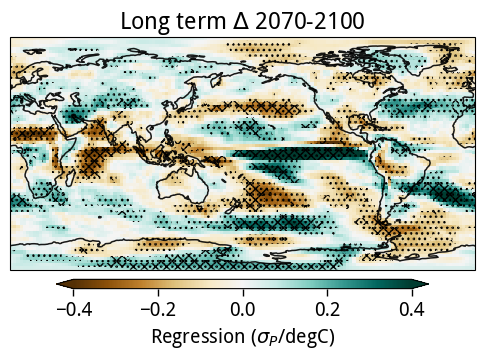

In [39]:
zz = delta_pr_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_endc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -0.4, vmax=0.4, cmap='BrBG', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Regression ($\sigma_P$/degC)'), transform=ccrs.PlateCarree())

zp_plot = np.ma.masked_greater_equal(zp, 0.05)
ax.pcolor(xx, yy, zp_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
# zp1_plot = np.ma.masked_less(zp1, 1)
# ax.pcolor(xx, yy, zp1_plot, alpha=0., hatch='...', transform=ccrs.PlateCarree())
zp2_plot = np.ma.masked_less(zp2, 1)
ax.pcolor(xx, yy, zp2_plot, alpha=0., hatch='xxx', transform=ccrs.PlateCarree())

ax.set_title('Long term $\Delta$ 2070-2100')
plot_background(ax)


In [93]:
M_baseline = pr_regr_smile_baseline_means.var('smile')
I_baseline = pr_regr_smile_baseline_vars.mean('smile')
T_baseline = M_baseline + I_baseline

In [94]:
M_midc = delta_pr_regr_smile_midc_means.var('smile')
I_midc = delta_pr_regr_smile_midc_vars.mean('smile')
T_midc = M_midc + I_midc

In [95]:
M_endc = delta_pr_regr_smile_endc_means.var('smile')
I_endc = delta_pr_regr_smile_endc_vars.mean('smile')
T_endc = M_endc + I_endc

In [96]:
plot_list = [
    M_baseline/T_baseline,
    M_midc/T_midc,
    M_endc/T_endc,
]

titles_list = [
    'Base period \n (1950 - 2014)',
    'Mid century \n (2030 - 2060)',
    'End century \n (2070 - 2100)',
]

labels_list = [
    'a',
    'b',
    'c',
]

In [97]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='RdYlBu_r', levels=np.linspace(0, 1, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Fractional Uncertainty', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': 'Mid century \n (2030 - 2060)'}, xlabel='lon', ylabel='lat'>

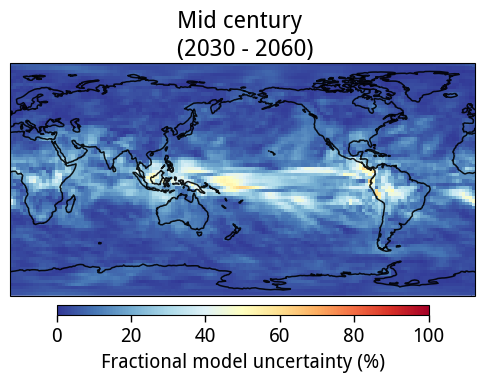

In [103]:
zz = plot_list[1]*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0, vmax=100, cmap='RdYlBu_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Fractional model uncertainty (%)'), transform=ccrs.PlateCarree())


ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': 'End century \n (2070 - 2100)'}, xlabel='lon', ylabel='lat'>

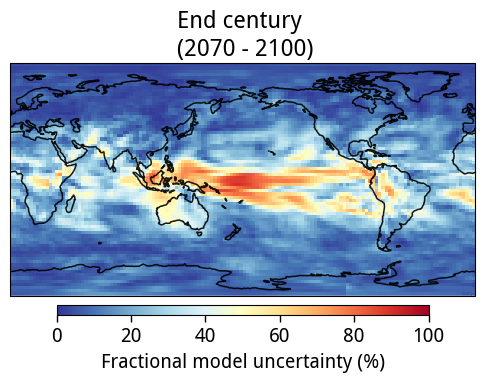

In [104]:
zz = plot_list[2]*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = 0, vmax=100, cmap='RdYlBu_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Fractional model uncertainty (%)'), transform=ccrs.PlateCarree())


ax.set_title(titles_list[2])
plot_background(ax)


In [83]:
plot_list = [
    (T_baseline) - ts_regr_cmip6_baseline.regr.var('model'),
    (T_midc) - ts_regr_cmip6_midc.regr.var('model'),
    (T_endc) - ts_regr_cmip6_endc.regr.var('model'),
]

titles_list = [
    'Baseline',
    'Mid century',
    'End century',
]

labels_list = [
    'a',
    'b',
    'c',
]

In [84]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='bwr', levels=np.linspace(-0.2, 0.2, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Relative uncertainty', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

<GeoAxes: title={'center': 'Mid century'}, xlabel='lon', ylabel='lat'>

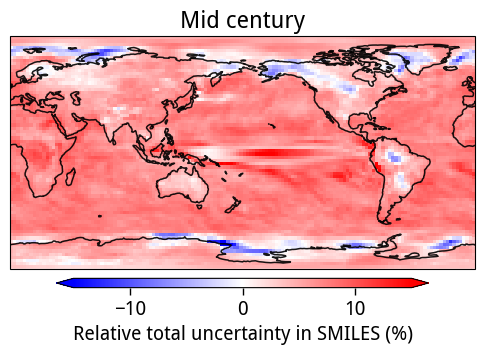

In [85]:
zz = plot_list[1]*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -15, vmax=15, cmap='bwr', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title(titles_list[1])
plot_background(ax)


<GeoAxes: title={'center': 'End century'}, xlabel='lon', ylabel='lat'>

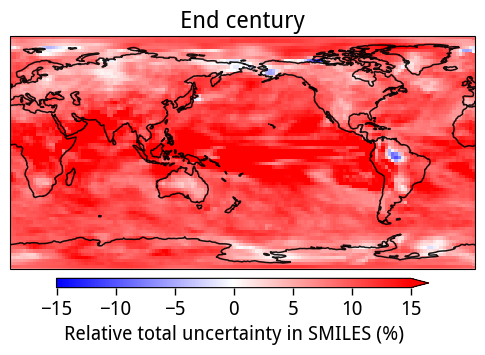

In [86]:
zz = plot_list[2]*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -15, vmax=15, cmap='bwr', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title(titles_list[2])
plot_background(ax)
